<a href="https://colab.research.google.com/github/bharatsharma2222/stats_practicals/blob/main/Practical8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
data = pd.read_csv("/content/diabetes.csv")

print(data.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [ ]:
print("Shape of dataset:", data.shape)

print("\nColumn names:")
print(data.columns)

print("\nDataset information:")
data.info()

print("\nStatistical summary:")
print(data.describe())


Shape of dataset: (768, 9)

Column names:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical su

In [ ]:
print(data.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


##**Feature Selection:Here we separate independent variables (X) and the dependent variable (y)**

In [ ]:
X = data.drop("Outcome", axis=1)

y = data["Outcome"]

print("Independent Variables (X):")
print(X.head())

print("\nDependent Variable (y):")
print(y.head())

Independent Variables (X):
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  
0                     0.627   50  
1                     0.351   31  
2                     0.672   32  
3                     0.167   21  
4                     2.288   33  

Dependent Variable (y):
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64


**Conclusion: The independent variables (X) and dependent variable (y) were successfully separated from the Pima Indians Diabetes dataset. The eight independent variables contain patient information, while the dependent variable Outcome indicates whether the patient has diabetes (1) or does not have diabetes (0). This separation prepares the dataset for training the Decision Tree Classifier.**

##**Split the dataset: We'll use 80% for training and 20% for testing.**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


##**Build Decision Tree: Your practical specifically asks for Entropy, so we'll use:**

In [ ]:
criterion="entropy"
model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

model.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

**Conclusion: The Decision Tree Classifier was successfully built using Scikit-learn with criterion="entropy". The model uses Entropy to measure the impurity of the dataset and Information Gain to select the best splits. The fit() function trained the model using the training data, enabling it to learn patterns for predicting whether a patient has diabetes.**

##**Prediction**

In [ ]:
y_pred = model.predict(X_test)

print("Predicted values:")
print(y_pred)

Predicted values:
[1 0 0 1 0 0 0 1 0 1 1 1 0 0 0 0 0 0 1 1 1 1 0 1 1 0 0 0 1 0 0 0 1 0 1 0 0
 0 1 1 0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 0 0 0 1 0 0 0 0 1 0 1 1 0 0 0 0 0 0 1
 0 1 0 1 0 0 0 1 0 0 0 0 1 1 1 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 1 0 1
 1 1 0 1 0 0 0 1 0 1 0 0 1 1 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 1 0]


##**Calculate Accuracy**

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")

Accuracy: 0.7012987012987013
Accuracy percentage: 70.12987012987013 %


##**Confusion Matrix**

In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[80 20]
 [26 28]]


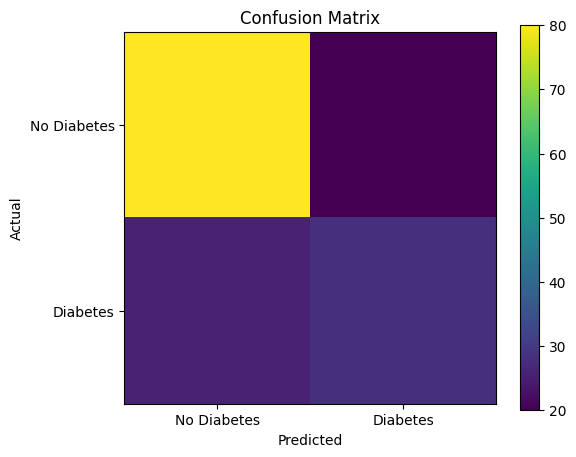

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["No Diabetes", "Diabetes"])
plt.yticks([0, 1], ["No Diabetes", "Diabetes"])

plt.colorbar()

plt.show()

##**Classification Report**

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.75      0.80      0.78       100
           1       0.58      0.52      0.55        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154



##**Visualize the Decision Tree**

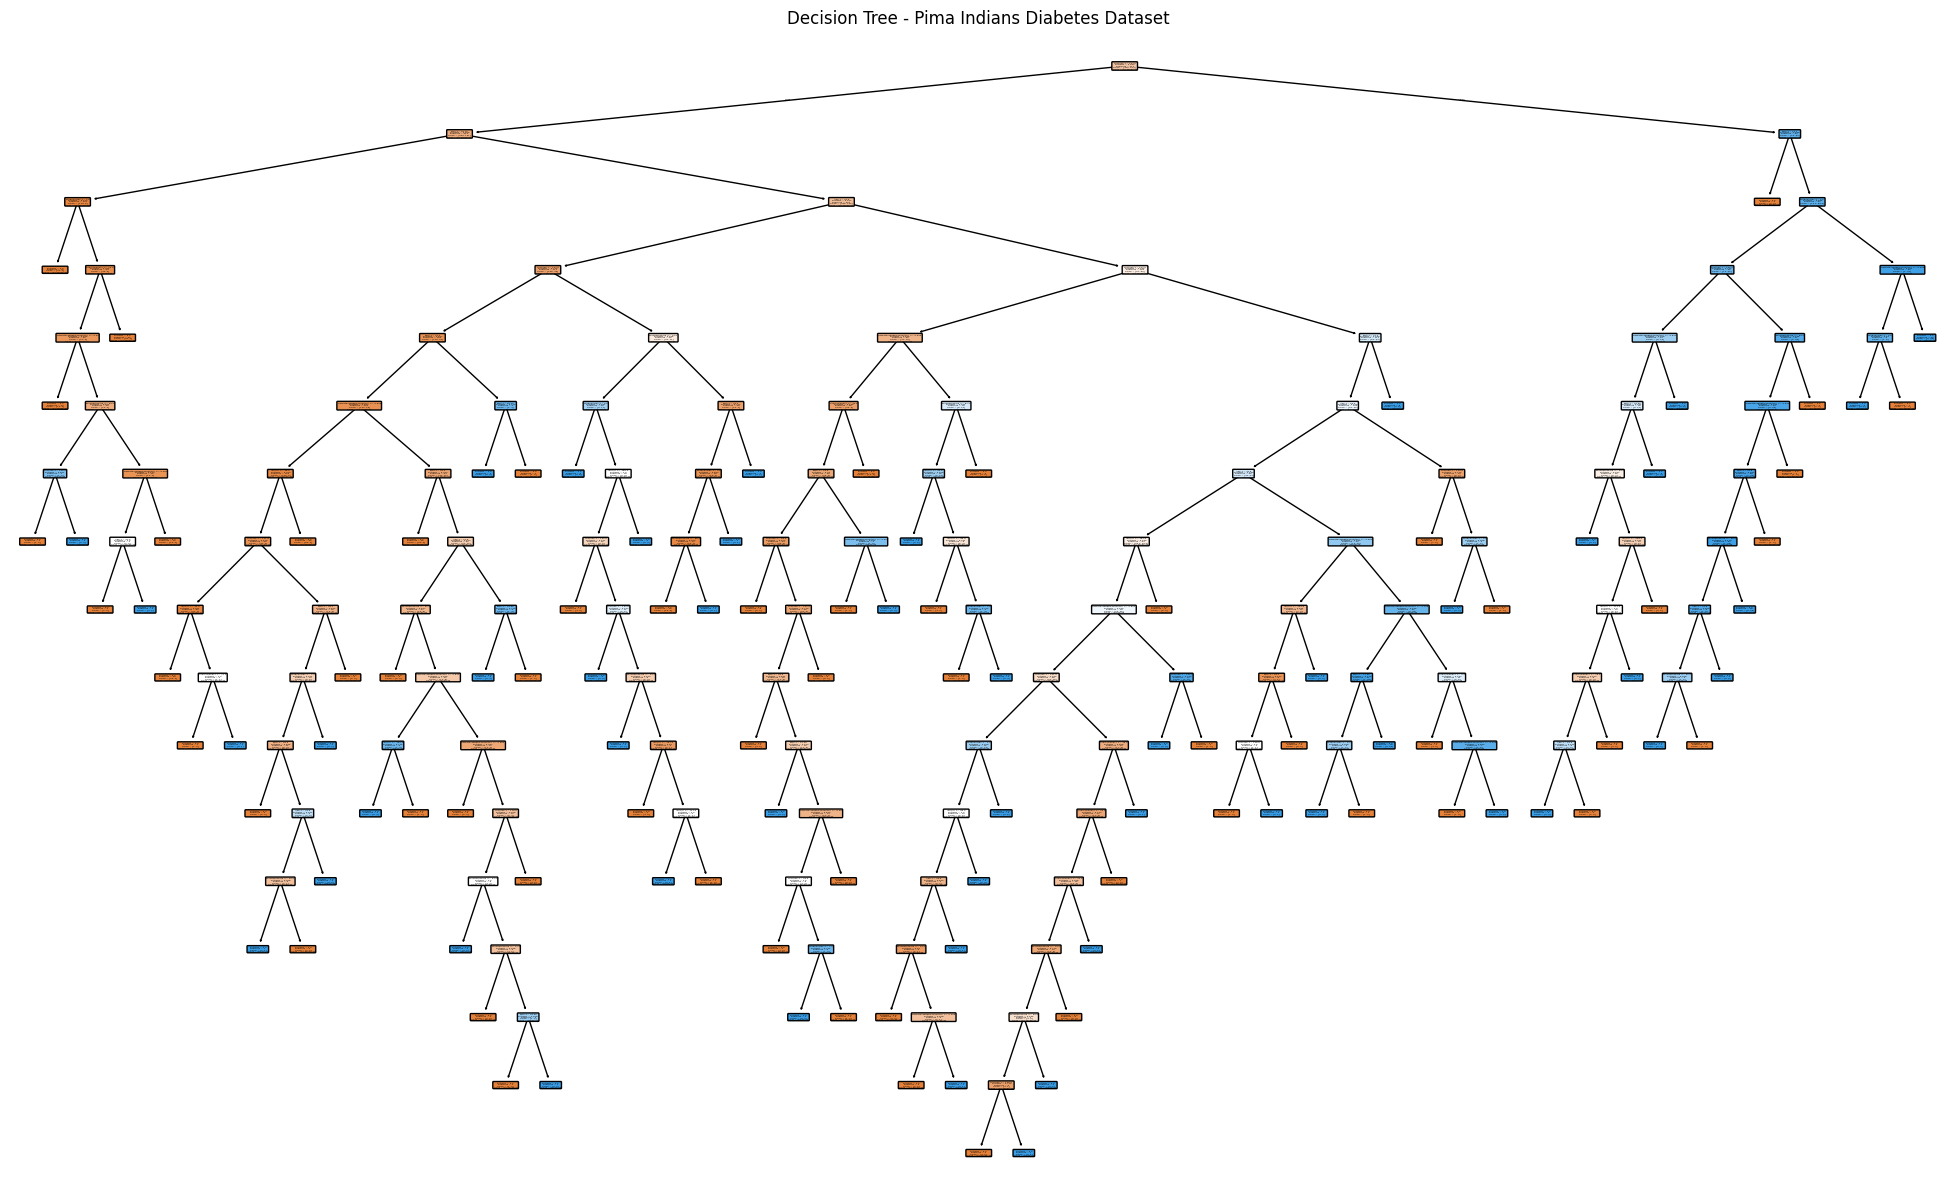

In [ ]:
plt.figure(figsize=(25, 15))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Pima Indians Diabetes Dataset")

plt.show()

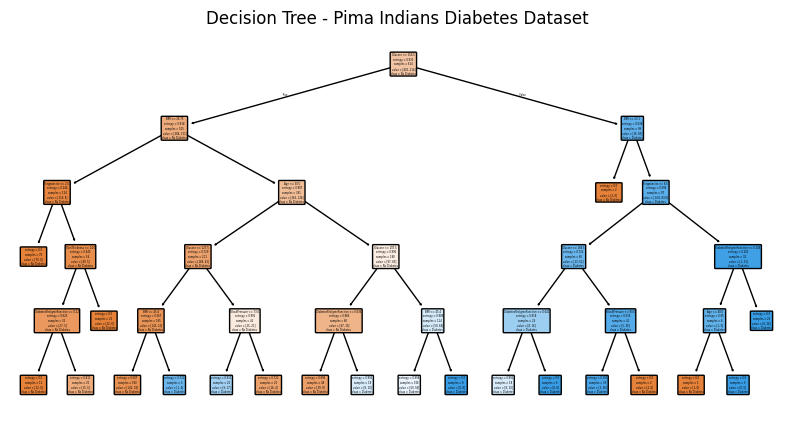

In [ ]:
model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

plt.figure(figsize=(10, 5))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Pima Indians Diabetes Dataset")

plt.show()

##**Calculate Entropy:Now we'll calculate the entropy of the target variable.**

In [ ]:
from math import log2

def entropy(y):
    values, counts = np.unique(y, return_counts=True)

    probabilities = counts / len(y)

    entropy_value = 0

    for p in probabilities:
        if p > 0:
            entropy_value -= p * log2(p)

    return entropy_value


parent_entropy = entropy(y_train)

print("Parent Entropy:", parent_entropy)

Parent Entropy: 0.932752156445529


**Conclusion: The Decision Tree was successfully visualized using Matplotlib and Scikit-learn. The tree shows how the model uses different features and decision rules to classify patients into two categories: Diabetes and No Diabetes. The colored nodes represent the predicted classes, while the branches show the decision paths. This visualization helps us understand how the model makes predictions based on patient data.**

##**Calculate Gini Index**

In [ ]:
def gini_index(y):
    values, counts = np.unique(y, return_counts=True)

    probabilities = counts / len(y)

    gini = 1 - np.sum(probabilities ** 2)

    return gini


parent_gini = gini_index(y_train)

print("Parent Gini Index:", parent_gini)

Parent Gini Index: 0.45411622404481755


##**Find the Root Node: The trained tree stores the feature selected at each node.**

In [ ]:
root_feature_index = model.tree_.feature[0]

root_feature = X.columns[root_feature_index]

root_threshold = model.tree_.threshold[0]

print("Root Feature:", root_feature)
print("Root Threshold:", root_threshold)

Root Feature: Glucose
Root Threshold: 154.5


##**Calculate Information Gain for Root:Now we'll calculate the Information Gain produced by the root split.**

In [ ]:
feature_values = X_train[root_feature]

left_data = y_train[feature_values <= root_threshold]

right_data = y_train[feature_values > root_threshold]

left_entropy = entropy(left_data)
right_entropy = entropy(right_data)

weighted_entropy = (
    (len(left_data) / len(y_train)) * left_entropy
    +
    (len(right_data) / len(y_train)) * right_entropy
)

information_gain = parent_entropy - weighted_entropy

print("Parent Entropy:", parent_entropy)
print("Left Node Entropy:", left_entropy)
print("Right Node Entropy:", right_entropy)
print("Weighted Entropy:", weighted_entropy)
print("Information Gain:", information_gain)

Parent Entropy: 0.932752156445529
Left Node Entropy: 0.8181295667728525
Right Node Entropy: 0.6381619453140062
Weighted Entropy: 0.7891119861141787
Information Gain: 0.14364017033135035


**Conclusion: The parent entropy was calculated as 0.933, while the weighted entropy after the root split was 0.789. The Information Gain was found to be 0.144, indicating that the root split reduces uncertainty in classifying patients as diabetic or non-diabetic. Therefore, the selected root split provides useful information for the Decision Tree Classifier.**

##**Calculate Gini after the split**

In [ ]:
left_gini = gini_index(left_data)
right_gini = gini_index(right_data)

weighted_gini = (
    (len(left_data) / len(y_train)) * left_gini
    +
    (len(right_data) / len(y_train)) * right_gini
)

print("Left Gini:", left_gini)
print("Right Gini:", right_gini)
print("Weighted Gini:", weighted_gini)

Left Gini: 0.379330756904515
Right Gini: 0.27099275584124083
Weighted Gini: 0.3618625775799806


##**Compare all features**

In [ ]:
def calculate_best_split(X_column, y):

    parent_entropy = entropy(y)

    values = np.sort(X_column.unique())

    best_gain = -1
    best_threshold = None

    for i in range(len(values) - 1):

        threshold = (values[i] + values[i + 1]) / 2

        left = y[X_column <= threshold]
        right = y[X_column > threshold]

        if len(left) == 0 or len(right) == 0:
            continue

        left_entropy = entropy(left)
        right_entropy = entropy(right)

        weighted_entropy = (
            len(left) / len(y) * left_entropy
            +
            len(right) / len(y) * right_entropy
        )

        gain = parent_entropy - weighted_entropy

        if gain > best_gain:
            best_gain = gain
            best_threshold = threshold

    return best_gain, best_threshold

In [ ]:
results = []

for feature in X_train.columns:

    gain, threshold = calculate_best_split(
        X_train[feature],
        y_train
    )

    results.append([
        feature,
        gain,
        threshold
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Feature",
        "Information Gain",
        "Best Threshold"
    ]
)

results_df = results_df.sort_values(
    by="Information Gain",
    ascending=False
)

print(results_df)

                    Feature  Information Gain  Best Threshold
1                   Glucose          0.143640        154.5000
5                       BMI          0.074059         29.6500
7                       Age          0.065433         27.5000
0               Pregnancies          0.038768          6.5000
4                   Insulin          0.036772        128.5000
6  DiabetesPedigreeFunction          0.024315          0.5275
3             SkinThickness          0.022859         32.5000
2             BloodPressure          0.018507         69.0000


**Conclusion: The Information Gain of all features was calculated and compared to identify the most suitable root node. Glucose achieved the highest Information Gain of 0.143640 at a threshold of 154.5, followed by BMI (0.074059) and Age (0.065433). Therefore, Glucose is the strongest candidate for the root node because it provides the greatest reduction in entropy among the features evaluated.**

##**Plot Information Gain:**

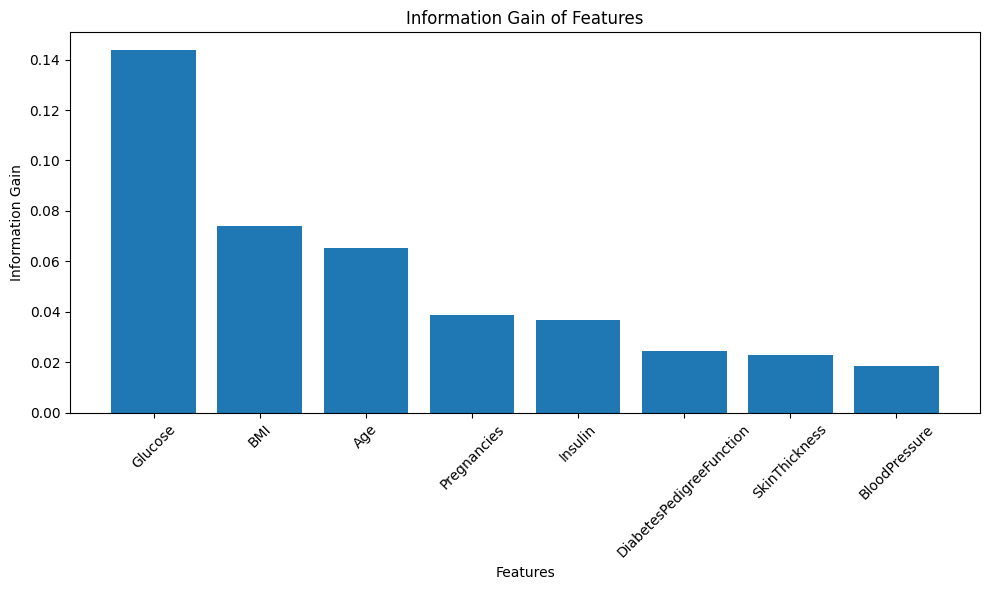

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    results_df["Feature"],
    results_df["Information Gain"]
)

plt.xlabel("Features")
plt.ylabel("Information Gain")
plt.title("Information Gain of Features")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

**Conclusion: The bar graph visually compares the Information Gain of all eight features. Glucose has the highest Information Gain (0.1436), followed by BMI (0.0741) and Age (0.0654), while BloodPressure has the lowest (0.0185). Therefore, Glucose is the most informative feature for the root split among the features evaluated, as it provides the greatest reduction in uncertainty when predicting diabetes.**

In [ ]:
best_feature = results_df.iloc[0]["Feature"]

best_gain = results_df.iloc[0]["Information Gain"]

best_threshold = results_df.iloc[0]["Best Threshold"]

print("Best Root Feature:", best_feature)
print("Highest Information Gain:", best_gain)
print("Best Threshold:", best_threshold)

Best Root Feature: Glucose
Highest Information Gain: 0.14364017033135035
Best Threshold: 154.5


The feature having the lowest weighted Gini Index produces the purest child nodes and is therefore considered the best split according to the Gini criterion. In our analysis, Glucose produced the lowest weighted Gini Index, indicating that it provides a strong separation between diabetic and non-diabetic observations. Therefore, Glucose is supported as a suitable root node.